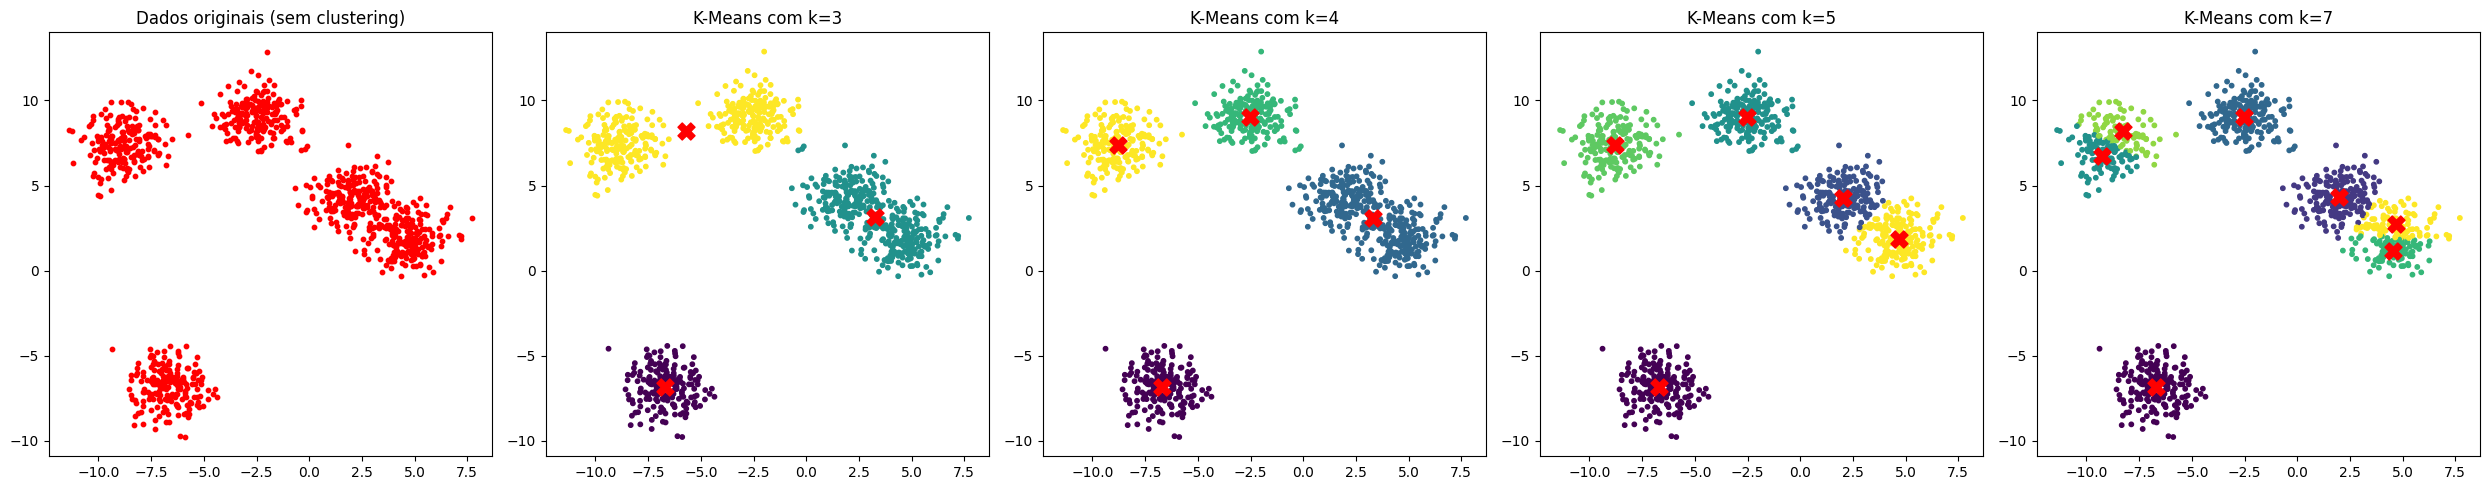

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=1000, centers=5, random_state=42)

k_values = [3, 4, 5, 7]

fig, axes = plt.subplots(1, len(k_values) + 1, figsize=(25, 5))

axes[0].scatter(X[:, 0], X[:, 1], color='red', s=10)
axes[0].set_title("Dados originais (sem clustering)")

for i, k in enumerate(k_values):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)

    axes[i + 1].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=10)
    axes[i + 1].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=150)
    axes[i + 1].set_title(f'K-Means com k={k}')

plt.tight_layout()
plt.show()

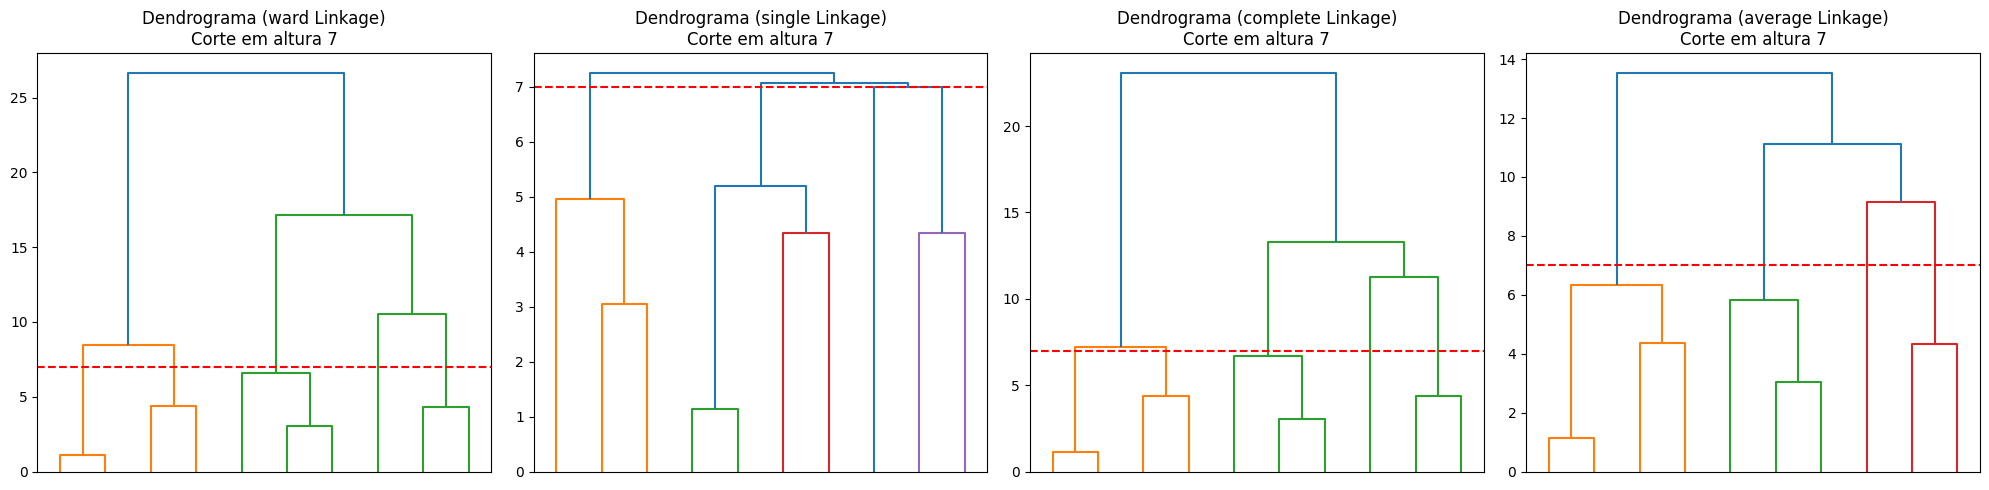

In [ ]:
import scipy.cluster.hierarchy as sch

X, _ = make_blobs(n_samples=10, centers=9, random_state=42)

linkage_methods = ["ward", "single", "complete", "average"]

altura_de_corte = 7

plt.figure(figsize=(20, 5))

for i, method in enumerate(linkage_methods):
    plt.subplot(1, 4, i + 1)

    linkage_matrix = sch.linkage(X, method=method)

    dendro = sch.dendrogram(linkage_matrix, no_labels=True)

    plt.axhline(y=altura_de_corte, color='red', linestyle='--')

    plt.title(f"Dendrograma ({method} Linkage)\nCorte em altura {altura_de_corte}")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

k_values = [3, 4, 5, 7]
silhouette_scores = []
davies_bouldin_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)

    silhouette = silhouette_score(X, labels)
    db_index = davies_bouldin_score(X, labels)

    silhouette_scores.append(silhouette)
    davies_bouldin_scores.append(db_index)

for i, k in enumerate(k_values):
    print(f"K={k} → Silhouette Score: {silhouette_scores[i]:.2f} | Davies-Bouldin Index: {davies_bouldin_scores[i]:.2f}")

K=3 → Silhouette Score: 0.48 | Davies-Bouldin Index: 0.65
K=4 → Silhouette Score: 0.45 | Davies-Bouldin Index: 0.58
K=5 → Silhouette Score: 0.45 | Davies-Bouldin Index: 0.42
K=7 → Silhouette Score: 0.33 | Davies-Bouldin Index: 0.25


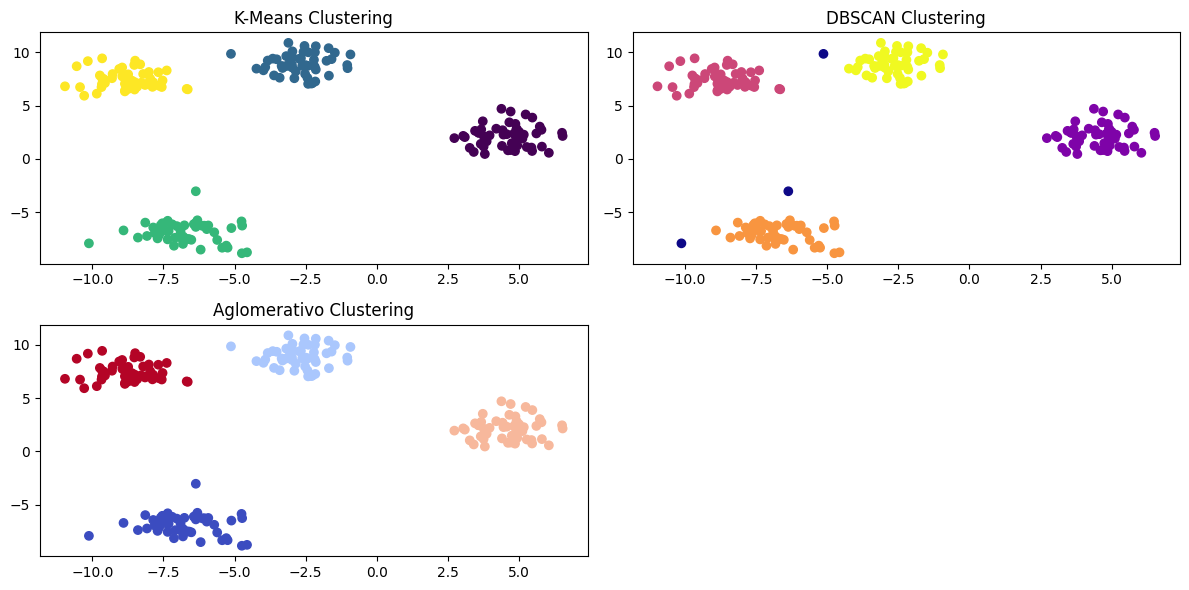

In [ ]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

X, _ = make_blobs(n_samples=200, centers=4, random_state=42)

kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=1.2, min_samples=5)
labels_dbscan = dbscan.fit_predict(X)

agglo = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agglo = agglo.fit_predict(X)

plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=labels_kmeans, cmap="viridis")
plt.title("K-Means Clustering")

plt.subplot(2, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=labels_dbscan, cmap="plasma")
plt.title("DBSCAN Clustering")

plt.subplot(2, 2, 3)
plt.scatter(X[:, 0], X[:, 1], c=labels_agglo, cmap="coolwarm")
plt.title("Aglomerativo Clustering")

plt.tight_layout()
plt.show()

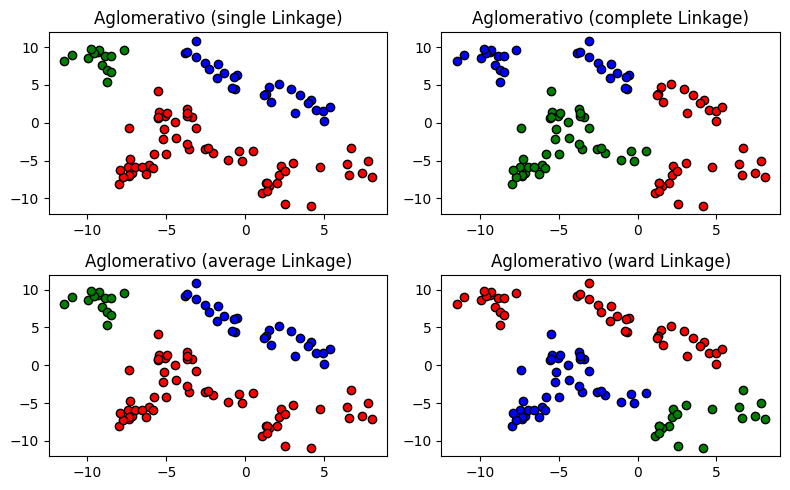

In [ ]:
X, _ = make_blobs(n_samples=100, centers=15, random_state=42)

colors = ["red", "blue", "green", "orange"]

linkage_methods = ["single", "complete", "average", "ward"]

plt.figure(figsize=(8, 5))

for i, method in enumerate(linkage_methods):
    plt.subplot(2, 2, i + 1)

    agglo = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = agglo.fit_predict(X)

    for cluster in range(4):
        plt.scatter(X[labels == cluster, 0], X[labels == cluster, 1],
                    color=colors[cluster], edgecolors="k")

    plt.title(f"Aglomerativo ({method} Linkage)")

plt.tight_layout()
plt.show()

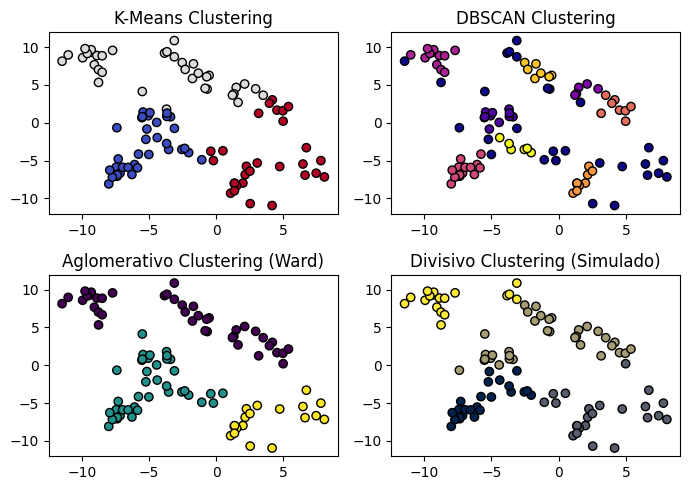

In [ ]:
X, _ = make_blobs(n_samples=100, centers=15, random_state=42)

colors = ["red", "blue", "green", "orange", "yellow", "purple", "magenta", "cyan", "lime", "black"]

kmeans = KMeans(n_clusters=3, random_state=42)
labels_kmeans = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=1.5, min_samples=5)
labels_dbscan = dbscan.fit_predict(X)

agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agglo = agglo.fit_predict(X)

def divisive_clustering(X, depth=2):
    if depth == 0 or len(X) <= 1:
        return np.zeros(len(X))

    kmeans = KMeans(n_clusters=2, random_state=42)
    labels = kmeans.fit_predict(X)

    sub_labels = np.zeros(len(X))
    for i in range(2):
        sub_labels[labels == i] = divisive_clustering(X[labels == i], depth - 1) + i * 2**depth

    return sub_labels

labels_divisive = divisive_clustering(X)

plt.figure(figsize=(7, 5))

plt.subplot(2, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=labels_kmeans, cmap="coolwarm", edgecolors="k")
plt.title("K-Means Clustering")

plt.subplot(2, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=labels_dbscan, cmap="plasma", edgecolors="k")
plt.title("DBSCAN Clustering")

plt.subplot(2, 2, 3)
plt.scatter(X[:, 0], X[:, 1], c=labels_agglo, cmap="viridis", edgecolors="k")
plt.title("Aglomerativo Clustering (Ward)")

plt.subplot(2, 2, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels_divisive, cmap="cividis", edgecolors="k")
plt.title("Divisivo Clustering (Simulado)")

plt.tight_layout()
plt.show()

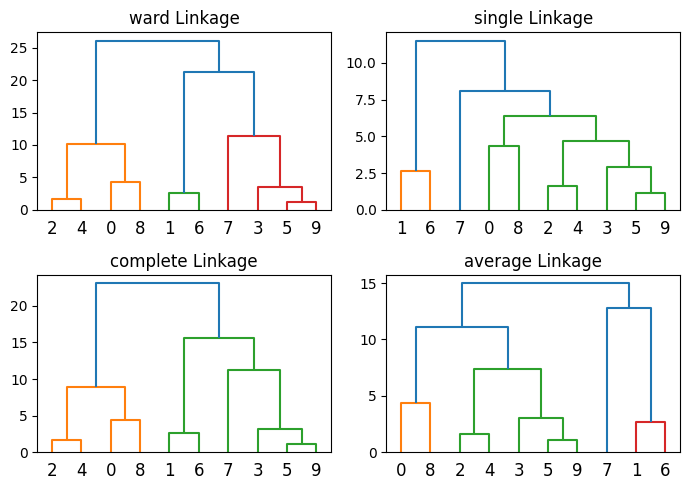

In [ ]:
X, _ = make_blobs(n_samples=10, centers=7, random_state=42)

linkage_methods = ["ward", "single", "complete", "average"]

plt.figure(figsize=(7, 5))

for i, method in enumerate(linkage_methods):
    plt.subplot(2, 2, i + 1)

    linkage_matrix = sch.linkage(X, method=method)
    sch.dendrogram(linkage_matrix)

    plt.title(f"{method} Linkage")

plt.tight_layout()
plt.show()

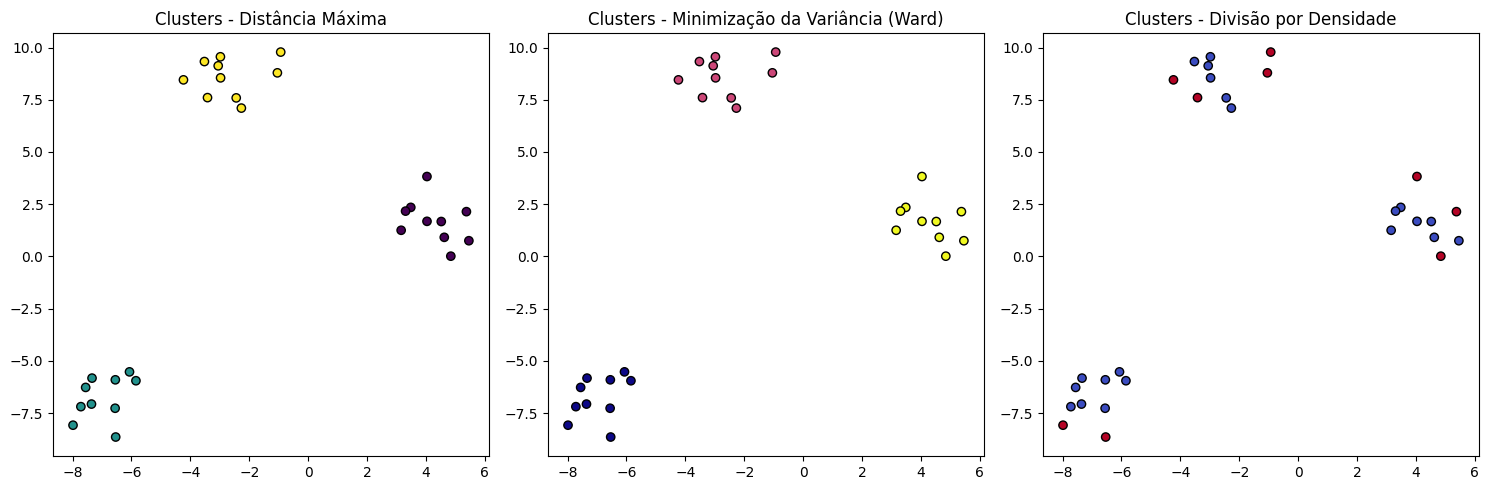

In [ ]:
from sklearn.neighbors import KernelDensity

np.random.seed(42)
X, _ = make_blobs(n_samples=30, centers=3, random_state=42)

cluster_max_dist = AgglomerativeClustering(n_clusters=3, linkage='complete').fit_predict(X)

cluster_ward = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X)

kde = KernelDensity(kernel='gaussian', bandwidth=0.5).fit(X)
densities = kde.score_samples(X)
density_threshold = np.percentile(densities, 30)
cluster_density = (densities < density_threshold).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(X[:, 0], X[:, 1], c=cluster_max_dist, cmap='viridis', edgecolors='black')
axes[0].set_title("Clusters - Distância Máxima")

axes[1].scatter(X[:, 0], X[:, 1], c=cluster_ward, cmap='plasma', edgecolors='black')
axes[1].set_title("Clusters - Minimização da Variância (Ward)")

scatter = axes[2].scatter(X[:, 0], X[:, 1], c=cluster_density, cmap='coolwarm', edgecolors='black')
axes[2].set_title("Clusters - Divisão por Densidade")

plt.tight_layout()
plt.show()

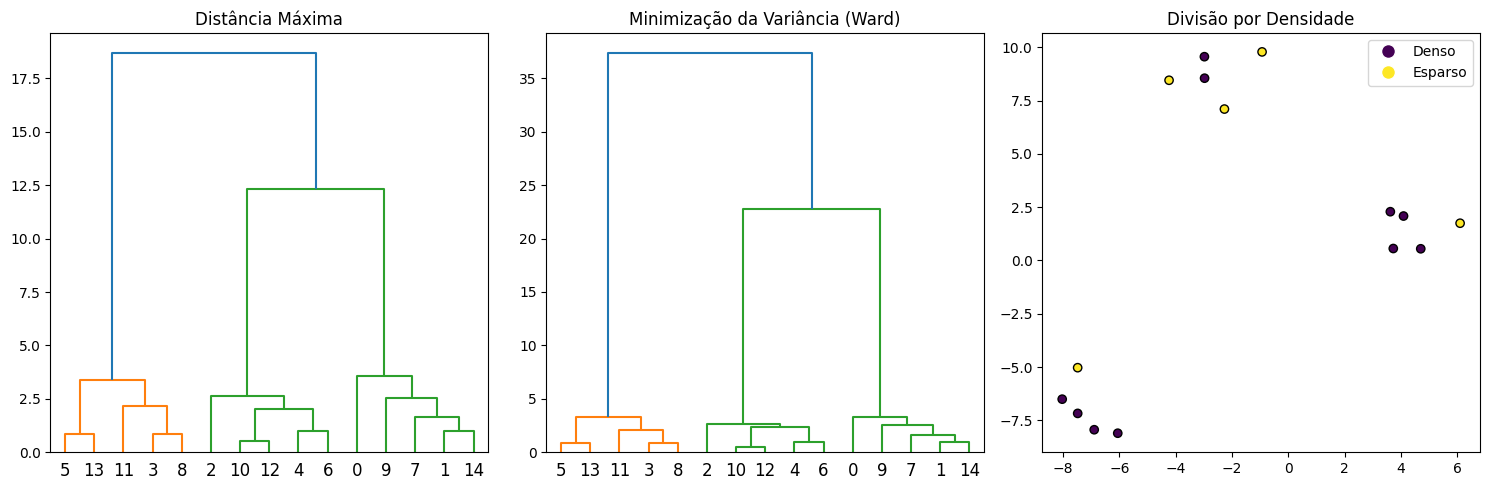

In [ ]:
np.random.seed(42)
X, _ = make_blobs(n_samples=15, centers=3, random_state=42)

linkage_max_dist = sch.linkage(X, method='complete')
linkage_ward = sch.linkage(X, method='ward')

kde = KernelDensity(kernel='gaussian', bandwidth=0.5).fit(X)
densities = kde.score_samples(X)
density_threshold = np.percentile(densities, 30)
density_labels = (densities < density_threshold).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].set_title("Distância Máxima")
sch.dendrogram(linkage_max_dist, ax=axes[0])

axes[1].set_title("Minimização da Variância (Ward)")
sch.dendrogram(linkage_ward, ax=axes[1])

axes[2].set_title("Divisão por Densidade")
scatter = axes[2].scatter(X[:, 0], X[:, 1], c=density_labels, cmap='viridis', edgecolors='black')
legend_labels = ["Denso", "Esparso"]
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=scatter.to_rgba(i), markersize=10) for i in range(2)]
axes[2].legend(handles, legend_labels, loc="upper right")

plt.tight_layout()
plt.show()

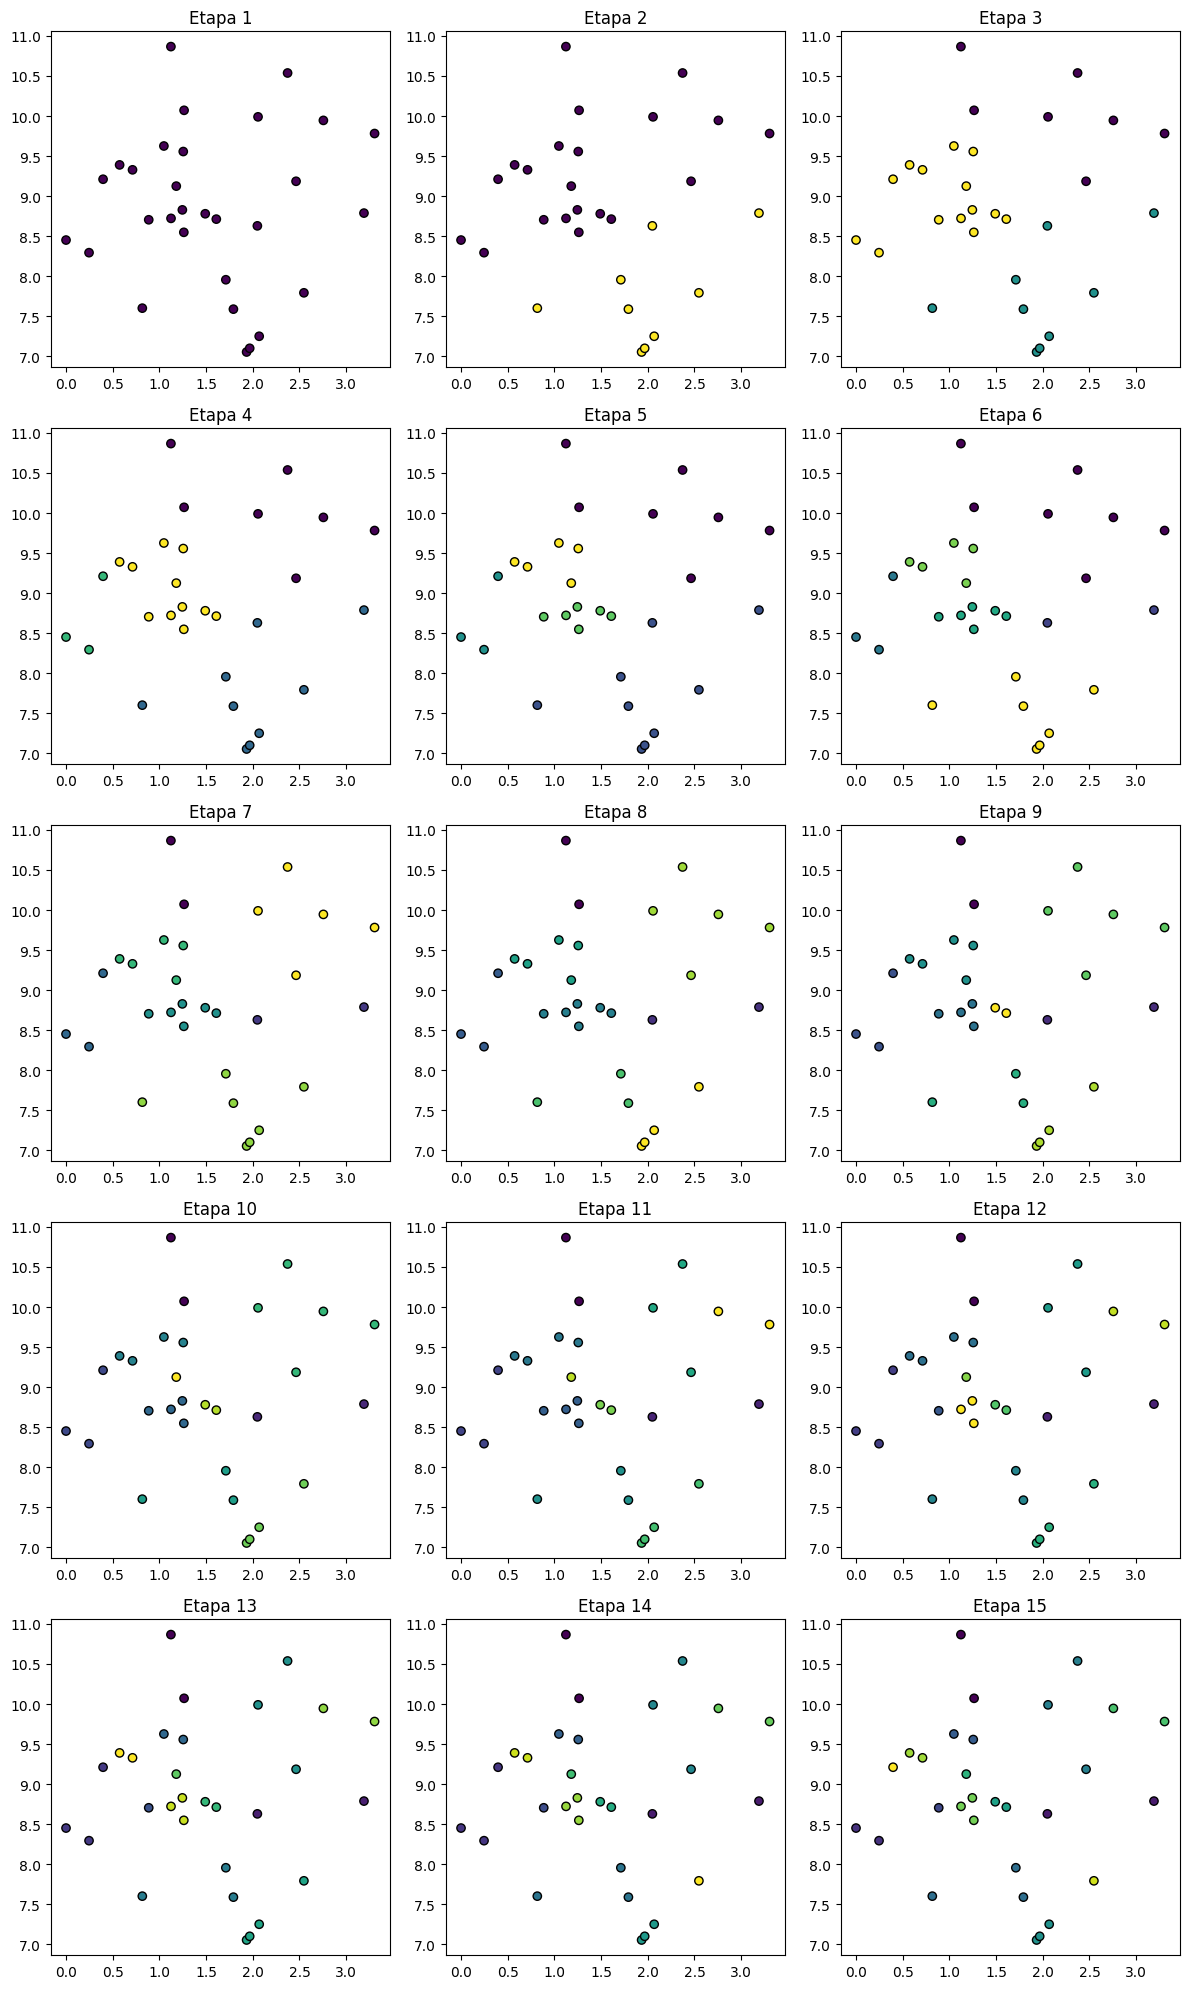

In [ ]:
np.random.seed(42)
X, _ = make_blobs(n_samples=30, centers=1, random_state=42)

X[:, 0] += np.abs(np.min(X[:, 0]))

def bisecting_kmeans_stepwise(X):
    labels = np.zeros(len(X), dtype=int)
    unique_clusters = [labels.copy()]

    while len(np.unique(labels)) < len(X) // 2:
        cluster_to_split = np.argmax(np.bincount(labels))
        mask = labels == cluster_to_split
        kmeans = KMeans(n_clusters=2, random_state=42).fit(X[mask])

        new_label = max(labels) + 1
        labels[mask] = np.where(kmeans.labels_ == 1, new_label, cluster_to_split)

        unique_clusters.append(labels.copy())

    return unique_clusters

cluster_steps = bisecting_kmeans_stepwise(X)

n_rows = (len(cluster_steps) + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(12, 4 * n_rows))

for i, labels in enumerate(cluster_steps):
    row, col = divmod(i, 3)
    axes[row, col].scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", edgecolors="black")
    axes[row, col].set_title(f"Etapa {i+1}")

for i in range(len(cluster_steps), n_rows * 3):
    row, col = divmod(i, 3)
    fig.delaxes(axes[row, col])

plt.tight_layout()
plt.show()

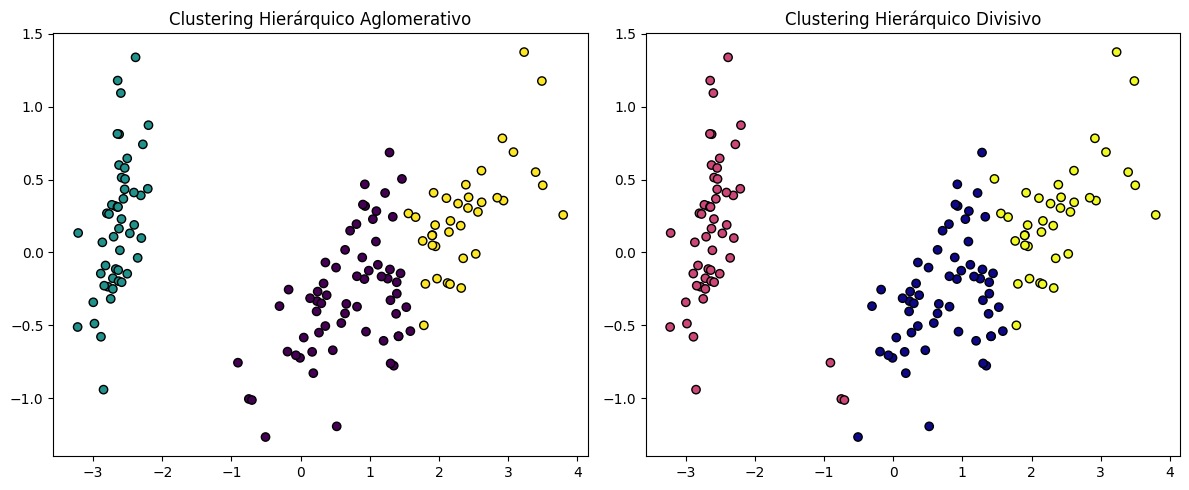

In [ ]:
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.spatial.distance import pdist, squareform

iris = load_iris()
X = iris.data
y_true = iris.target

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

agglo_cluster = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_pca)

def bisecting_kmeans(X, num_clusters=3):
    labels = np.zeros(len(X), dtype=int)
    while len(np.unique(labels)) < num_clusters:
        largest_cluster = np.argmax(np.bincount(labels))
        mask = labels == largest_cluster
        kmeans = KMeans(n_clusters=2, random_state=42).fit(X[mask])
        new_label = max(labels) + 1
        labels[mask] = np.where(kmeans.labels_ == 1, new_label, largest_cluster)
    return labels

divisive_cluster = bisecting_kmeans(X_pca, num_clusters=3)

silhouette_agglo = silhouette_score(X_pca, agglo_cluster)
silhouette_divisive = silhouette_score(X_pca, divisive_cluster)

davies_bouldin_agglo = davies_bouldin_score(X_pca, agglo_cluster)
davies_bouldin_divisive = davies_bouldin_score(X_pca, divisive_cluster)

rand_agglo = adjusted_rand_score(y_true, agglo_cluster)
rand_divisive = adjusted_rand_score(y_true, divisive_cluster)

def dunn_index(X, labels):
    cluster_distances = pdist(X)
    inter_cluster_distances = np.min(squareform(cluster_distances)[labels[:, None] != labels])
    intra_cluster_diameter = np.max([np.max(pdist(X[labels == i])) for i in np.unique(labels)])
    return inter_cluster_distances / intra_cluster_diameter

dunn_agglo = dunn_index(X_pca, agglo_cluster)
dunn_divisive = dunn_index(X_pca, divisive_cluster)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=agglo_cluster, cmap="viridis", edgecolors="black")
axes[0].set_title("Clustering Hierárquico Aglomerativo")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=divisive_cluster, cmap="plasma", edgecolors="black")
axes[1].set_title("Clustering Hierárquico Divisivo")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
df_metrics = pd.DataFrame({
    "Métrica": ["Coeficiente de Silhueta", "Índice de Dunn", "Davies-Bouldin", "Rand Ajustado"],
    "Aglomerativo": [silhouette_agglo, dunn_agglo, davies_bouldin_agglo, rand_agglo],
    "Divisivo": [silhouette_divisive, dunn_divisive, davies_bouldin_divisive, rand_divisive]
})

print("\n📊 Tabela de Métricas:\n")
print(df_metrics.to_markdown(index=False))


📊 Tabela de Métricas:

| Métrica                 |   Aglomerativo |   Divisivo |
|:------------------------|---------------:|-----------:|
| Coeficiente de Silhueta |      0.598475  |  0.587864  |
| Índice de Dunn          |      0.0742531 |  0.0681225 |
| Davies-Bouldin          |      0.560496  |  0.568969  |
| Rand Ajustado           |      0.744526  |  0.680872  |


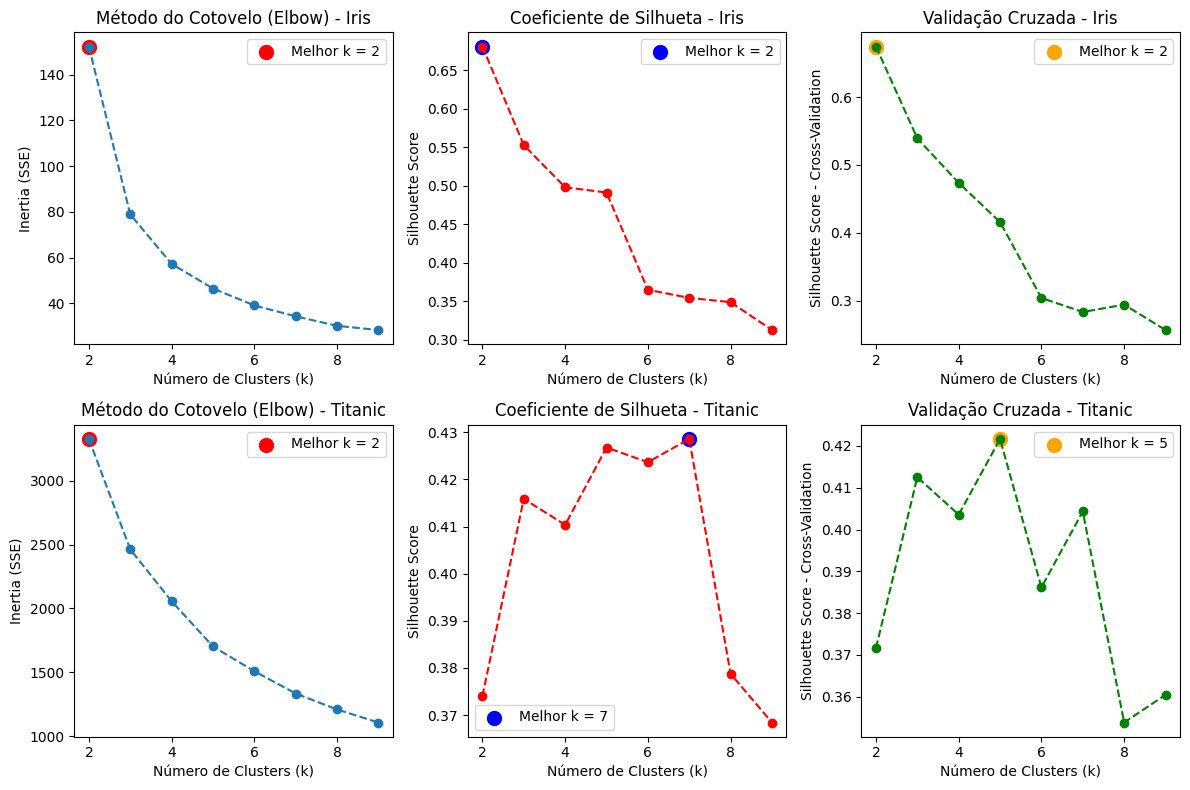

In [ ]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold

def load_data():
    iris = load_iris()
    X_iris = iris.data

    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    df_titanic = pd.read_csv(url)
    X_titanic = df_titanic[["Age", "Fare", "Pclass", "SibSp", "Parch"]]

    imputer, scaler = SimpleImputer(strategy="mean"), StandardScaler()
    X_titanic = scaler.fit_transform(imputer.fit_transform(X_titanic))

    return X_iris, X_titanic

def compute_metrics(X):
    k_values = range(2, 10)
    inertia, silhouette, cv_scores = [], [], []
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertia.append(kmeans.inertia_)
        silhouette.append(silhouette_score(X, kmeans.labels_))

        fold_scores = []
        for train_index, test_index in kf.split(X, np.zeros(X.shape[0])):
            X_train, X_test = X[train_index], X[test_index]
            kmeans.fit(X_train)
            labels = kmeans.predict(X_test)
            fold_scores.append(silhouette_score(X_test, labels))

        cv_scores.append(np.mean(fold_scores))

    return k_values, inertia, silhouette, cv_scores, k_values[np.argmin(np.gradient(inertia))], k_values[np.argmax(silhouette)], k_values[np.argmax(cv_scores)]

X_iris, X_titanic = load_data()
iris_metrics = compute_metrics(X_iris)
titanic_metrics = compute_metrics(X_titanic)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, (metrics, title) in enumerate([(iris_metrics, "Iris"), (titanic_metrics, "Titanic")]):
    k_values, inertia, silhouette, cv_scores, best_k_elbow, best_k_silhouette, best_k_cv = metrics

    axes[i, 0].plot(k_values, inertia, marker="o", linestyle="--")
    axes[i, 0].scatter(best_k_elbow, inertia[k_values.index(best_k_elbow)], color="red", s=100, label=f"Melhor k = {best_k_elbow}")
    axes[i, 0].set_title(f"Método do Cotovelo (Elbow) - {title}")
    axes[i, 0].set_xlabel("Número de Clusters (k)")
    axes[i, 0].set_ylabel("Inertia (SSE)")
    axes[i, 0].legend()

    axes[i, 1].plot(k_values, silhouette, marker="o", linestyle="--", color="r")
    axes[i, 1].scatter(best_k_silhouette, silhouette[k_values.index(best_k_silhouette)], color="blue", s=100, label=f"Melhor k = {best_k_silhouette}")
    axes[i, 1].set_title(f"Coeficiente de Silhueta - {title}")
    axes[i, 1].set_xlabel("Número de Clusters (k)")
    axes[i, 1].set_ylabel("Silhouette Score")
    axes[i, 1].legend()

    axes[i, 2].plot(k_values, cv_scores, marker="o", linestyle="--", color="g")
    axes[i, 2].scatter(best_k_cv, cv_scores[k_values.index(best_k_cv)], color="orange", s=100, label=f"Melhor k = {best_k_cv}")
    axes[i, 2].set_title(f"Validação Cruzada - {title}")
    axes[i, 2].set_xlabel("Número de Clusters (k)")
    axes[i, 2].set_ylabel("Silhouette Score - Cross-Validation")
    axes[i, 2].legend()

plt.tight_layout()
plt.show()

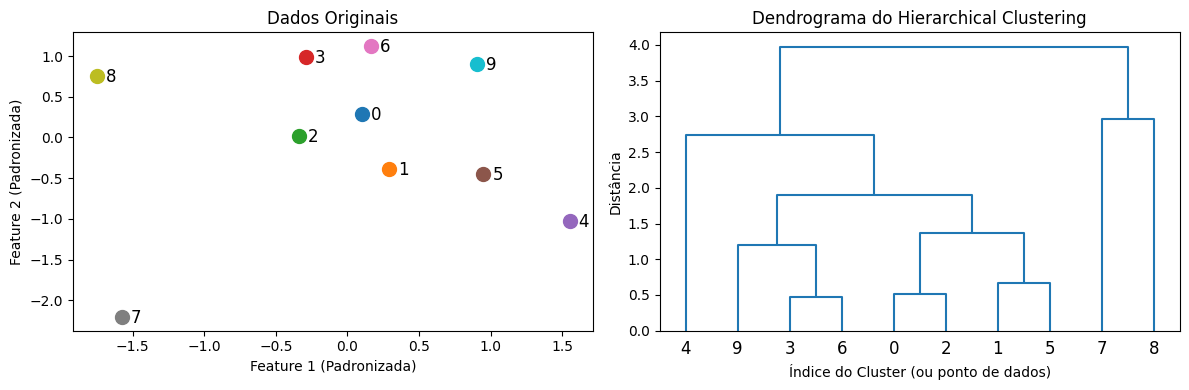

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import fcluster

np.random.seed(0)
X = np.random.rand(10, 2)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for i, (x, y) in enumerate(zip(X_scaled[:, 0], X_scaled[:, 1])):
    plt.scatter(x, y, c=[plt.cm.tab10(i)], s=100)
    plt.text(x + 0.1, y - 0.01, f'{i}', color="black", fontsize=12, ha='center', va='center')
plt.title('Dados Originais')
plt.xlabel('Feature 1 (Padronizada)')
plt.ylabel('Feature 2 (Padronizada)')

plt.subplot(1, 2, 2)
dendrogram(Z, color_threshold=0)
plt.title('Dendrograma do Hierarchical Clustering')
plt.xlabel('Índice do Cluster (ou ponto de dados)')
plt.ylabel('Distância')
plt.tight_layout()
plt.show()

Com o dendrograma e os dados originais plotados, o próximo passo é decidir quantos clusters são desejados. Isso pode ser feito identificando os cortes no dendrograma onde as ligações entre clusters começam a se estender verticalmente, indicando uma maior distância entre os clusters. Esses cortes representam o número de clusters que podem ser considerados.

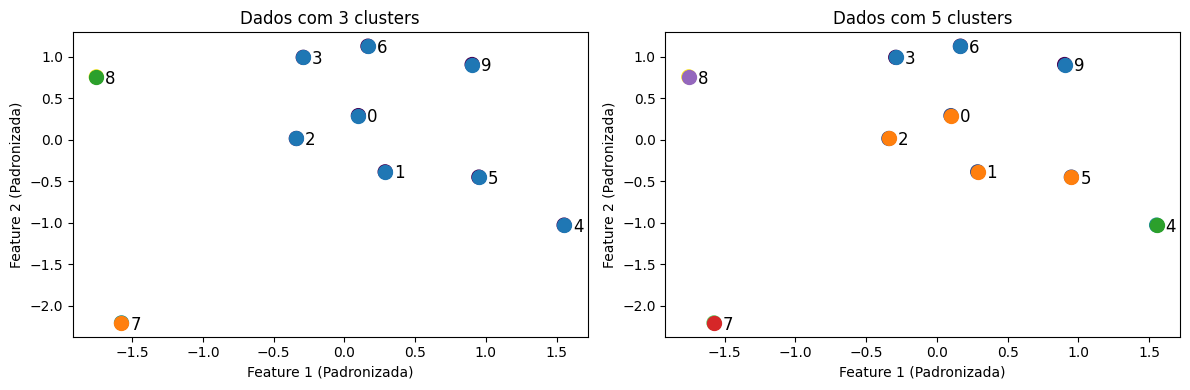

In [ ]:
num_clusters_1 = 3
num_clusters_2 = 5

cluster_labels_1 = fcluster(Z, num_clusters_1, criterion='maxclust')
cluster_labels_2 = fcluster(Z, num_clusters_2, criterion='maxclust')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=cluster_labels_1, cmap='viridis', s=100)
axes[0].set_title('Dados com 3 clusters')
axes[0].set_xlabel('Feature 1 (Padronizada)')
axes[0].set_ylabel('Feature 2 (Padronizada)')

for i, (x, y) in enumerate(zip(X_scaled[:, 0], X_scaled[:, 1])):
    axes[0].scatter(x, y, c=[plt.cm.tab10(cluster_labels_1[i] - 1)], s=100)
    axes[0].text(x + 0.1, y - 0.02, f'{i}', color="black", fontsize=12, ha='center', va='center')

axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=cluster_labels_2, cmap='viridis', s=100)
axes[1].set_title('Dados com 5 clusters')
axes[1].set_xlabel('Feature 1 (Padronizada)')
axes[1].set_ylabel('Feature 2 (Padronizada)')

for i, (x, y) in enumerate(zip(X_scaled[:, 0], X_scaled[:, 1])):
    axes[1].scatter(x, y, c=[plt.cm.tab10(cluster_labels_2[i] - 1)], s=100)
    axes[1].text(x + 0.1, y - 0.02, f'{i}', color="black", fontsize=12, ha='center', va='center')

plt.tight_layout()
plt.show()